In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Cargar los resultados del Resumen Maestro
try:
    df = pd.read_csv('resumen_maestro_joint.csv')
except FileNotFoundError:
    print("Error: No se encontró el archivo 'resumen_maestro_joint.csv'.")
    exit()

# 2. Calcular Media y Desviación Estándar por Modelo
# Agrupamos por 'Modelo' y calculamos estadísticas para Test y CV
stats = df.groupby('Modelo').agg({
    'Test_Acc': ['mean', 'std'],
    'CV_Acc': ['mean', 'std']
}).reset_index()

# Limpiamos los nombres de las columnas para facilitar el acceso
stats.columns = ['Modelo', 'Test_Acc_mean', 'Test_Acc_std', 'CV_Acc_mean', 'CV_Acc_std']

# Ordenar los modelos por el Accuracy de Test promedio (de mejor a peor)
#stats = stats.sort_values(by='Test_Acc_mean', ascending=False)

# ── Configuración ──────────────────────────────────────────────────────────────
MODALIDADES  = ['Morfológicos', 'Metabólicos', 'DTI']
ALGORITMOS   = ['ElasticNet', 'KNN', 'SVM', 'RF', 'CatBoost', 'MLP']
METRICAS     = ['CV_Acc', 'Test_Acc', 'Precision', 'Recall', 'F1']
SEEDS        = [7, 14, 21, 28, 35]
OUT_DIR      = 'resultados_temprana'
PALETTE      = sns.color_palette('tab10', n_colors=len(ALGORITMOS))
ALGO_COLOR_MAP    = dict(zip(ALGORITMOS, PALETTE))
MOD_COLORS   = {'Morfológicos': '#DD8452', 'Metabólicos': '#55A868', 'DTI': '#4C72B0'}

os.makedirs(f'{OUT_DIR}/tablas',  exist_ok=True)
os.makedirs(f'{OUT_DIR}/figuras', exist_ok=True)

# Paleta anatómica con lateralidad
COLORES_ROI = {
    'amig_der': '#E84545',  # rojo intenso
    'amig_izq': '#F4A0A0',  # rojo claro
    'hip_der':  '#2E86AB',  # azul intenso
    'hip_izq':  '#90CAE4',  # azul claro
    'tal_der':  '#4CAF50',  # verde intenso
    'tal_izq':  '#A8D8A8',  # verde claro
}



In [2]:
stats

,Modelo,Test_Acc_mean,Test_Acc_std,CV_Acc_mean,CV_Acc_std
0,CatBoost,0.888889,0.000000,0.809524,0.033672
1,ElasticNet,0.788889,0.024845,0.814286,0.031044
2,KNN,0.944444,0.000000,0.861905,0.010648
3,MLP,0.888889,0.068041,0.833333,0.023810
4,RF,0.911111,0.030429,0.833333,0.029161
5,SVM,0.877778,0.024845,0.876190,0.031044


In [3]:
df.head()

,Seed,Modelo,Selector,k,CV_Acc,Test_Acc,Precision,Recall,F1,Params
0,7,RF,KBest_mutual_info_classif,48,0.880952,0.888889,0.888889,0.888889,0.888889,"{'model__criterion': 'gini', 'model__max_depth..."
1,7,SVM,KBest_mutual_info_classif,48,0.904762,0.888889,0.916667,0.888889,0.885714,"{'model__C': 0.1, 'model__gamma': 0.001, 'mode..."
2,7,CatBoost,KBest_mutual_info_classif,60,0.833333,0.888889,0.888889,0.888889,0.888889,"{'model__depth': 7, 'model__iterations': 1000,..."
3,7,KNN,KBest_f_classif,48,0.857143,0.944444,0.952381,0.944444,0.944056,"{'model__leaf_size': 5, 'model__metric': 'eucl..."
4,7,ElasticNet,KBest_mutual_info_classif,60,0.857143,0.777778,0.833333,0.777778,0.738095,"{'model__alpha': 0.0001, 'model__l1_ratio': 0...."


  ✅ Fig 3 guardada: Comparativa modelos


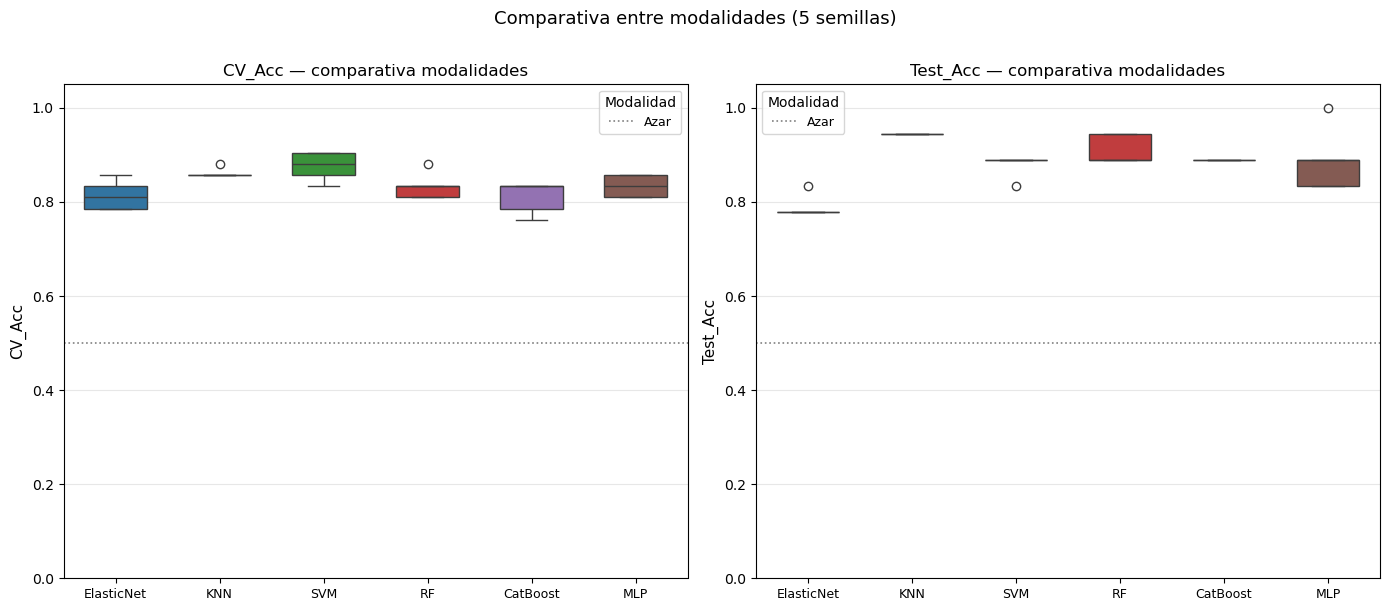

In [5]:
# ══════════════════════════════════════════════════════════════════════
# FIGURA 3 — Boxplot comparativa algoritmos
# ══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, metric in zip(axes, ['CV_Acc', 'Test_Acc']):
    sns.boxplot(data=df, x='Modelo', y=metric,
                hue='Modelo', order=ALGORITMOS,
                palette=PALETTE, width=0.6,
                hue_order=ALGO_COLOR_MAP, ax=ax)
    ax.axhline(1/2, color='gray', linestyle=':', lw=1.2, label='Azar')
    ax.set_ylim(0, 1.05)
    ax.set_title(f'{metric} — comparativa modalidades', fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel(metric, fontsize=11)
    ax.legend(title='Modalidad', fontsize=9)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', labelsize=9)

plt.suptitle('Comparativa entre modalidades (5 semillas)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figuras/03_comparativa_modelos.png',
            dpi=150, bbox_inches='tight')
#plt.close()
print('  ✅ Fig 3 guardada: Comparativa modelos')

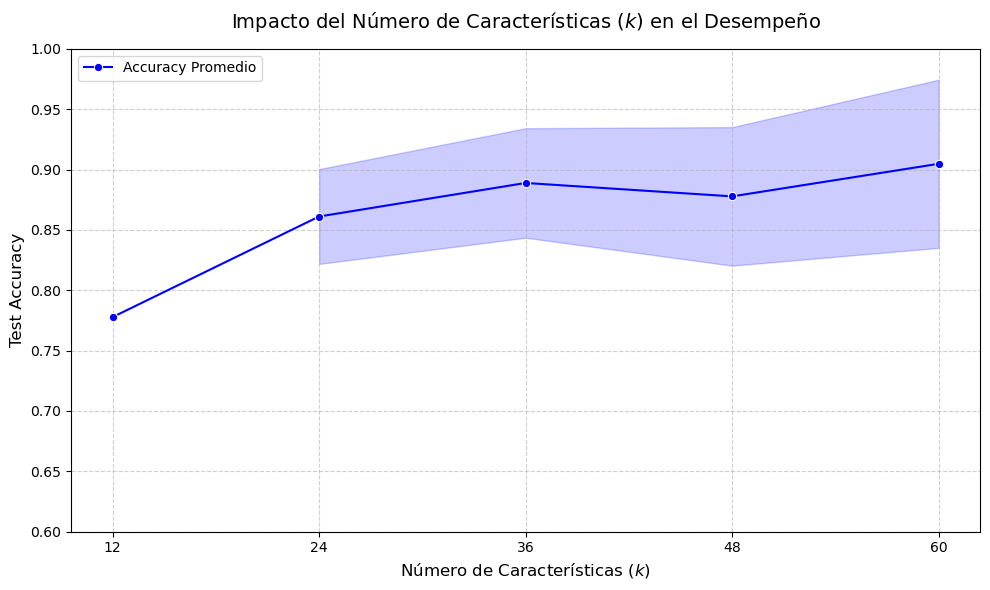

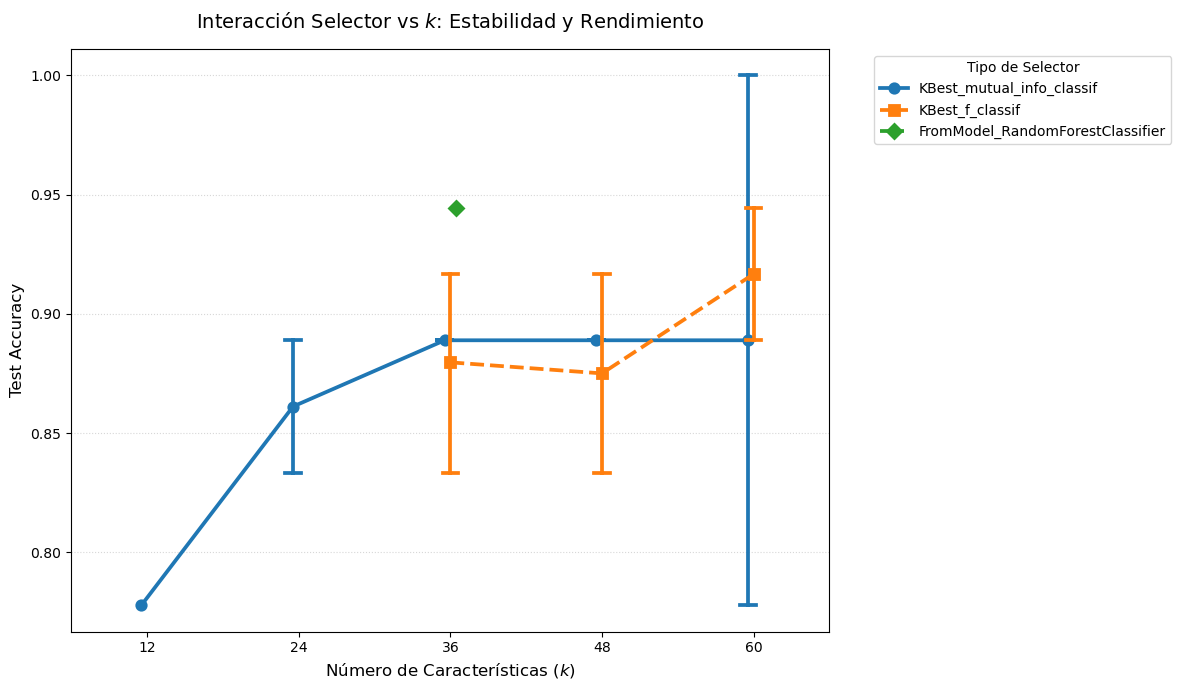

¡Gráficas generadas! Se han guardado como 'grafica_impacto_k.png' y 'grafica_interaccion_selector_k.png'


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar los datos
df = pd.read_csv('resumen_maestro_joint.csv')

# --- GRÁFICA 1: IMPACTO DEL NÚMERO DE CARACTERÍSTICAS (k) ---
plt.figure(figsize=(10, 6))

# Calculamos la media y desviación por cada k para la banda de error
k_stats = df.groupby('k')['Test_Acc'].agg(['mean', 'std']).reset_index()

sns.lineplot(data=df, x='k', y='Test_Acc', marker='o', color='blue', label='Accuracy Promedio', errorbar='sd')

plt.title('Impacto del Número de Características ($k$) en el Desempeño', fontsize=14, pad=15)
plt.xlabel('Número de Características ($k$)', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.xticks(df['k'].unique()) # Asegura que se vean todos los valores de k
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0.6, 1.0) # Ajustado para ver mejor la progresión
plt.legend()

plt.tight_layout()
plt.savefig('grafica_impacto_k.png', dpi=300)
plt.show()


# --- GRÁFICA 2: INTERACCIÓN SELECTOR VS k ---
plt.figure(figsize=(12, 7))

# Usamos pointplot para ver cómo se comporta cada selector en cada k
sns.pointplot(data=df, x='k', y='Test_Acc', hue='Selector', 
              markers=['o', 's', 'D'], linestyles=['-', '--', '-.'],
              capsize=.1, dodge=True)

plt.title('Interacción Selector vs $k$: Estabilidad y Rendimiento', fontsize=14, pad=15)
plt.xlabel('Número de Características ($k$)', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.grid(True, axis='y', linestyle=':', alpha=0.5)
plt.legend(title='Tipo de Selector', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('grafica_interaccion_selector_k.png', dpi=300)
plt.show()

print("¡Gráficas generadas! Se han guardado como 'grafica_impacto_k.png' y 'grafica_interaccion_selector_k.png'")

C:\Users\rrdia\AppData\Local\Temp\ipykernel_21444\3216480235.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_stability, x='ROI', y='Rank', palette='Set3')


Análisis completado. Archivos generados: 'consenso_rois_frecuencia.png', 'estabilidad_ranking_rois.png' y 'estadisticas_biomarcadores_final.csv'


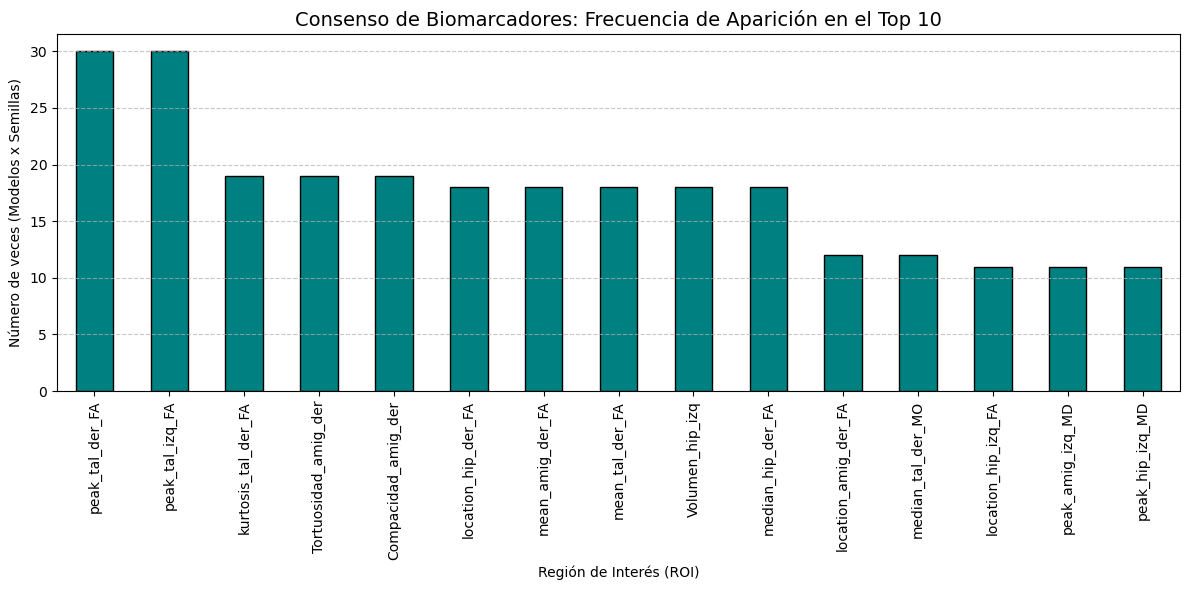

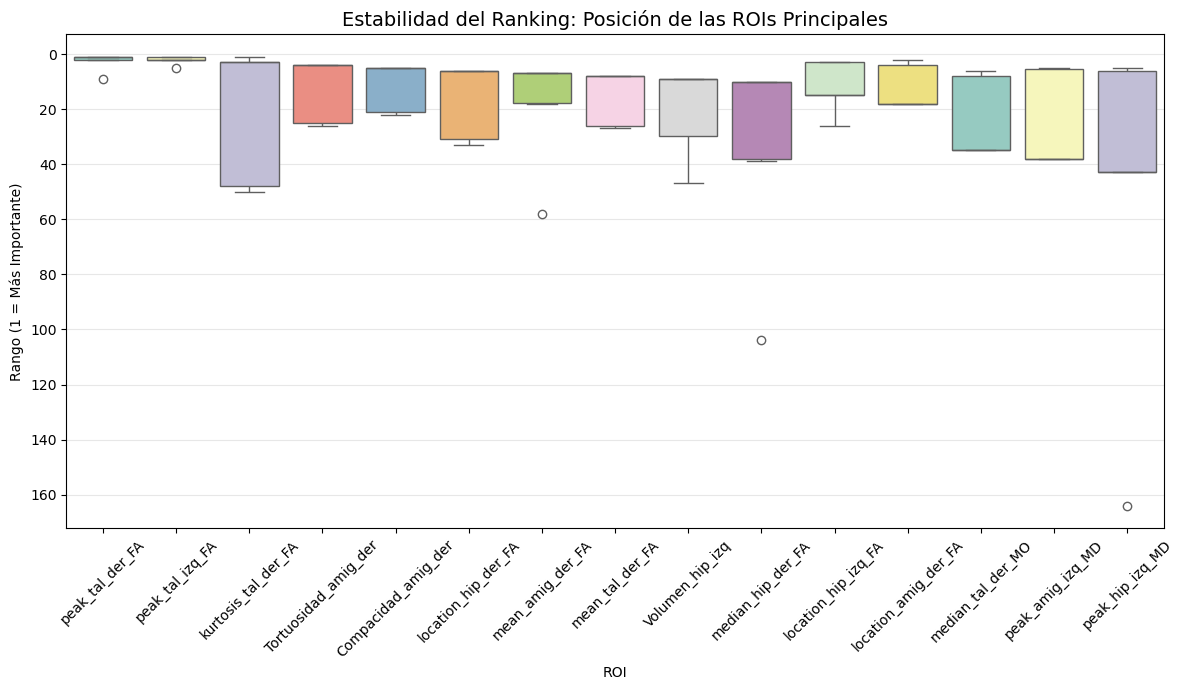

In [7]:
import pandas as pd
import glob
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Recolectar todos los archivos de importancia generados
archivos_roi = glob.glob('importancia_ROIs_*.csv')

if not archivos_roi:
    print("No se encontraron archivos de importancia. Asegúrate de haber corrido el Joint Search.")
else:
    lista_df = []
    for f in archivos_roi:
        # Extraer modelo y semilla del nombre del archivo para trazabilidad
        partes = f.replace('.csv', '').split('_')
        modelo = partes[2]
        semilla = partes[3]
        
        temp_df = pd.read_csv(f)
        temp_df['Modelo'] = modelo
        temp_df['Semilla'] = semilla
        # Crear columna de Rango (1 es el más importante)
        temp_df['Rank'] = temp_df['Importancia'].rank(ascending=False)
        lista_df.append(temp_df)

    # DataFrame Maestro de ROIs
    df_rois = pd.concat(lista_df)

    # --- ANÁLISIS 1: FRECUENCIA EN EL TOP 10 (HISTOGRAMA) ---
    top_10_count = df_rois[df_rois['Rank'] <= 10]['ROI'].value_counts().head(15)

    plt.figure(figsize=(12, 6))
    top_10_count.plot(kind='bar', color='teal', edgecolor='black')
    plt.title('Consenso de Biomarcadores: Frecuencia de Aparición en el Top 10', fontsize=14)
    plt.ylabel('Número de veces (Modelos x Semillas)')
    plt.xlabel('Región de Interés (ROI)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig('consenso_rois_frecuencia.png')

    # --- ANÁLISIS 2: ESTADÍSTICAS DE LUGAR (RANKING) ---
    # Filtramos las ROIs más frecuentes para ver su estabilidad de rango
    top_rois_names = top_10_count.index.tolist()
    df_stability = df_rois[df_rois['ROI'].isin(top_rois_names)]

    plt.figure(figsize=(12, 7))
    sns.boxplot(data=df_stability, x='ROI', y='Rank', palette='Set3')
    plt.gca().invert_yaxis() # Invertimos para que el 1 (mejor) esté arriba
    plt.title('Estabilidad del Ranking: Posición de las ROIs Principales', fontsize=14)
    plt.ylabel('Rango (1 = Más Importante)')
    plt.xticks(rotation=45)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('estabilidad_ranking_rois.png')

    # --- ANÁLISIS 3: VALOR DE IMPORTANCIA NORMALIZADO ---
    # Debido a que ANOVA y RF tienen escalas distintas, normalizamos por modelo
    df_rois['Imp_Norm'] = df_rois.groupby(['Modelo', 'Semilla'])['Importancia'].transform(lambda x: (x - x.min()) / (x.max() - x.min()))
    
    stats_rois = df_rois.groupby('ROI').agg({
        'Imp_Norm': ['mean', 'std'],
        'Rank': ['mean', 'median', 'min']
    }).reset_index()
    stats_rois.columns = ['ROI', 'Imp_Media', 'Imp_STD', 'Rank_Medio', 'Rank_Mediana', 'Mejor_Rank']
    stats_rois = stats_rois.sort_values(by='Rank_Medio')

    # Guardar estadísticas
    stats_rois.to_csv('estadisticas_biomarcadores_todos.csv', index=False)
    stats_rois.head(60).to_csv('estadisticas_biomarcadores_top60.csv', index=False)
    print("Análisis completado. Archivos generados: 'consenso_rois_frecuencia.png', 'estabilidad_ranking_rois.png' y 'estadisticas_biomarcadores_final.csv'")

C:\Users\rrdia\AppData\Local\Temp\ipykernel_21444\1787840838.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mod_data.values, y=mod_data.index, ax=axes[i], palette='magma')
C:\Users\rrdia\AppData\Local\Temp\ipykernel_21444\1787840838.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mod_data.values, y=mod_data.index, ax=axes[i], palette='magma')
C:\Users\rrdia\AppData\Local\Temp\ipykernel_21444\1787840838.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mod_data.values, y=mod_data.index, ax=axes[i], palette='magma')
C:\User

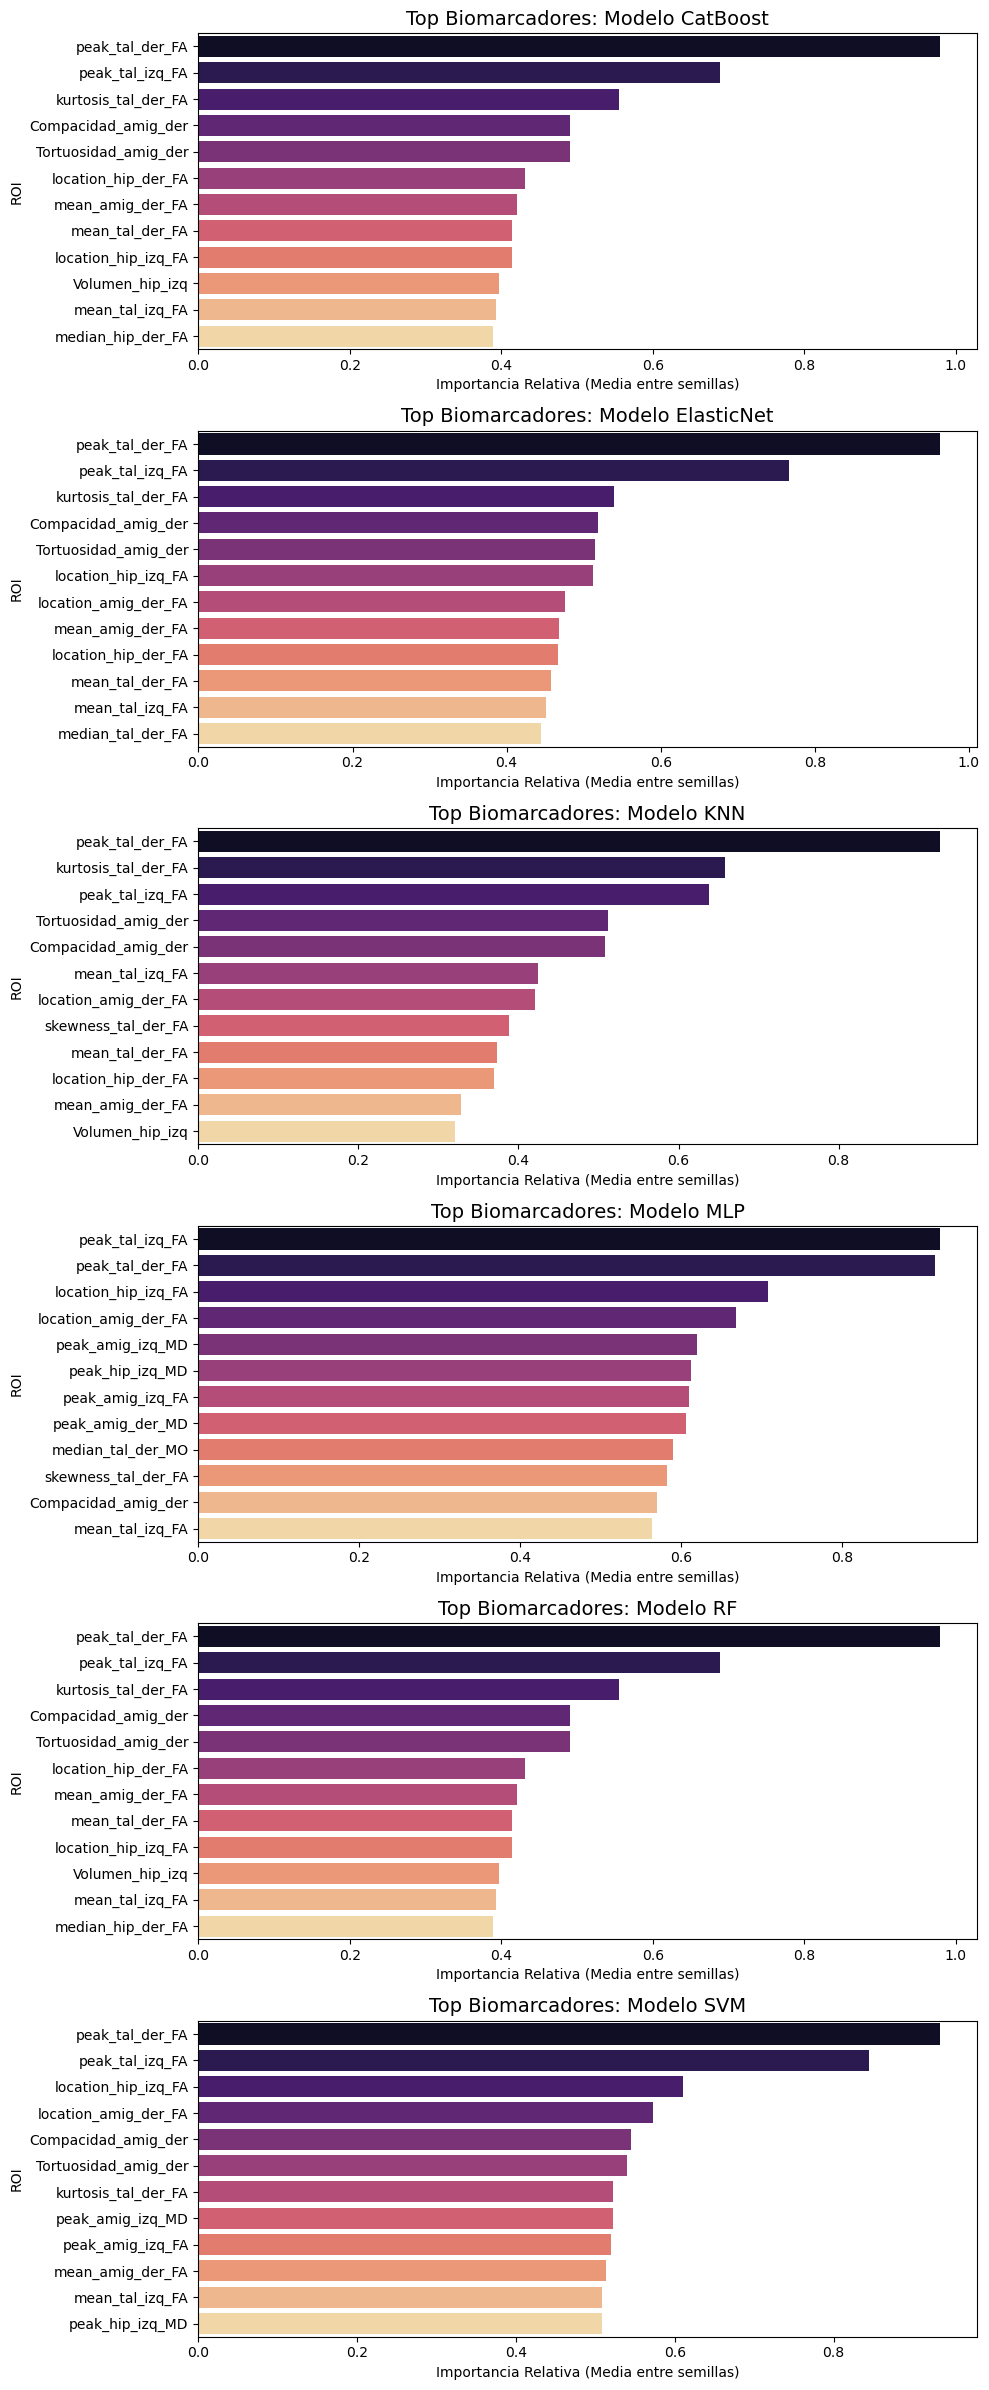

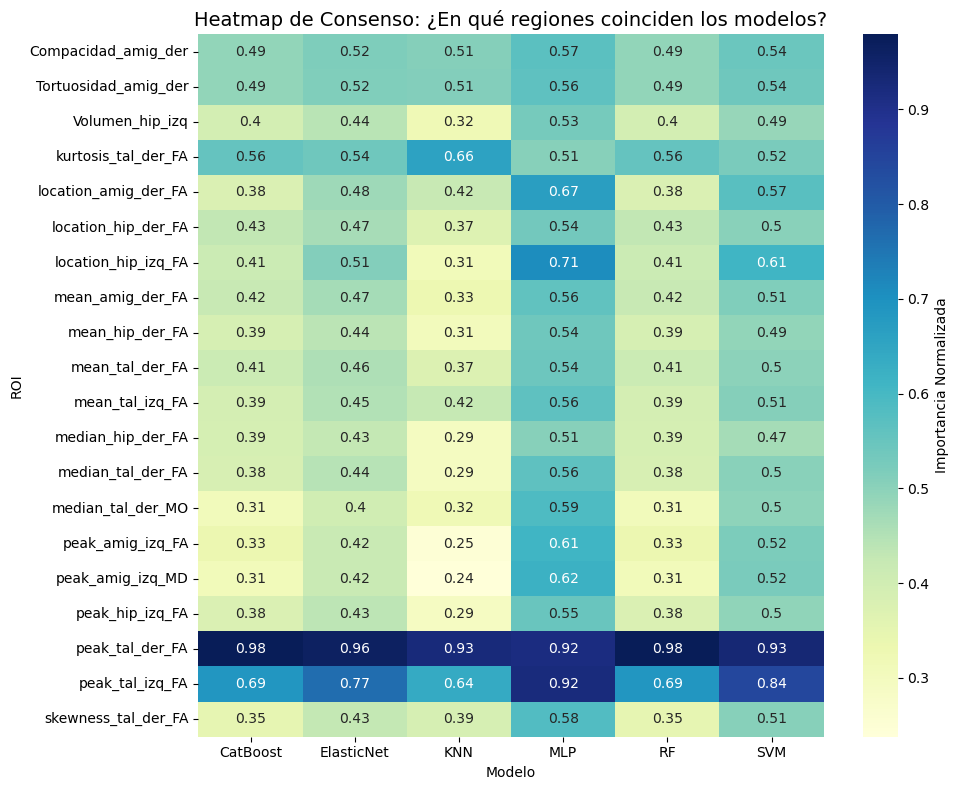

Análisis finalizado. Se han generado 'importancias_por_modelo.png' y 'heatmap_consenso_modelos.png'


In [8]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y Normalizar Datos
archivos_roi = glob.glob('importancia_ROIs_*.csv')

if not archivos_roi:
    print("No se encontraron archivos. Asegúrate de ejecutar primero el script de búsqueda.")
else:
    all_data = []
    for f in archivos_roi:
        # Extraer info del nombre: importancia_ROIs_Modelo_sSemilla.csv
        parts = f.replace('.csv', '').split('_')
        modelo = parts[2]
        
        df_temp = pd.read_csv(f)
        # Normalizar importancia entre 0 y 1 para poder comparar modelos
        mi = df_temp['Importancia'].min()
        ma = df_temp['Importancia'].max()
        if ma - mi > 0:
            df_temp['Imp_Norm'] = (df_temp['Importancia'] - mi) / (ma - mi)
        else:
            df_temp['Imp_Norm'] = 0
            
        df_temp['Modelo'] = modelo
        all_data.append(df_temp)

    df_master = pd.concat(all_data)

    # 2. Generar Gráficos por Modelo (Top 10 ROIs)
    modelos = df_master['Modelo'].unique()
    fig, axes = plt.subplots(len(modelos), 1, figsize=(10, 4 * len(modelos)))
    
    if len(modelos) == 1: axes = [axes]

    for i, mod in enumerate(modelos):
        # Promediar importancia entre todas las semillas para este modelo
        mod_data = df_master[df_master['Modelo'] == mod].groupby('ROI')['Imp_Norm'].mean().sort_values(ascending=False).head(12)
        
        sns.barplot(x=mod_data.values, y=mod_data.index, ax=axes[i], palette='magma')
        axes[i].set_title(f'Top Biomarcadores: Modelo {mod}', fontsize=14)
        axes[i].set_xlabel('Importancia Relativa (Media entre semillas)')

    plt.tight_layout()
    plt.savefig('importancias_por_modelo.png', dpi=300)
    plt.show()

    # 3. Heatmap de Consenso (Comparativa Cruzada)
    # Seleccionamos las 20 ROIs más importantes en promedio global
    top_global = df_master.groupby('ROI')['Imp_Norm'].mean().sort_values(ascending=False).head(20).index
    
    pivot_df = df_master[df_master['ROI'].isin(top_global)].pivot_table(
        index='ROI', columns='Modelo', values='Imp_Norm', aggfunc='mean'
    )

    plt.figure(figsize=(10, 8))
    sns.heatmap(pivot_df, annot=True, cmap='YlGnBu', cbar_kws={'label': 'Importancia Normalizada'})
    plt.title('Heatmap de Consenso: ¿En qué regiones coinciden los modelos?', fontsize=14)
    plt.tight_layout()
    plt.savefig('heatmap_consenso_modelos.png', dpi=300)
    plt.show()

    print("Análisis finalizado. Se han generado 'importancias_por_modelo.png' y 'heatmap_consenso_modelos.png'")